In [1]:
from matminer.datasets import load_dataset

In [2]:
steels = load_dataset("matbench_steels")

In [5]:
print(steels.iloc[1][1])
print(steels.head())

1123.1
                                         composition  yield strength
0  Fe0.620C0.000953Mn0.000521Si0.00102Cr0.000110N...          2411.5
1  Fe0.623C0.00854Mn0.000104Si0.000203Cr0.147Ni0....          1123.1
2  Fe0.625Mn0.000102Si0.000200Cr0.0936Ni0.129Mo0....          1736.3
3  Fe0.634C0.000478Mn0.000523Si0.00102Cr0.000111N...          2487.3
4  Fe0.636C0.000474Mn0.000518Si0.00101Cr0.000109N...          2249.6


C:\Users\stlma\AppData\Local\Temp\ipykernel_32272\2348380598.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(steels.iloc[1][1])


Example datapoint:
Composition: Fe0.620C0.000953Mn0.000521Si0.00102Cr0.000110Ni0.192Mo0.0176V0.000112Nb0.0000616Co0.146Al0.00318Ti0.0185
Yield Strength: 2411.5

Total datapoints: 312
Valid compositions: 312
Nonzero yield strengths: 312
Total viable datapoints: 312


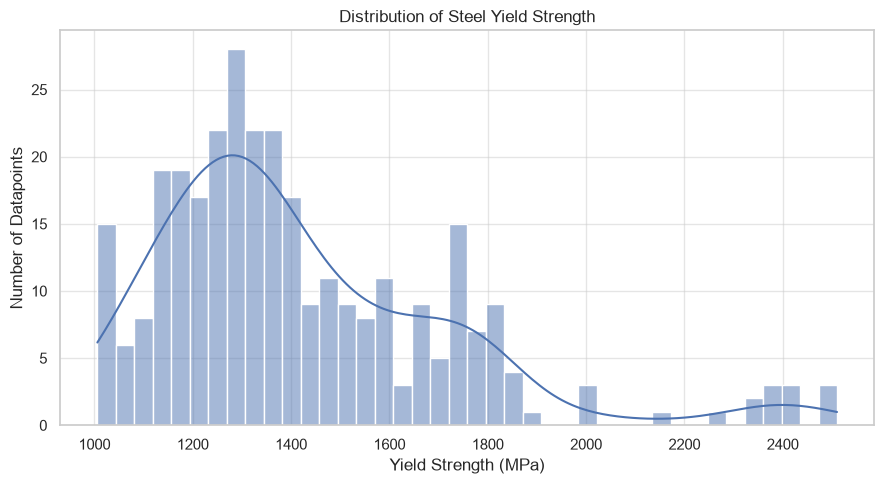

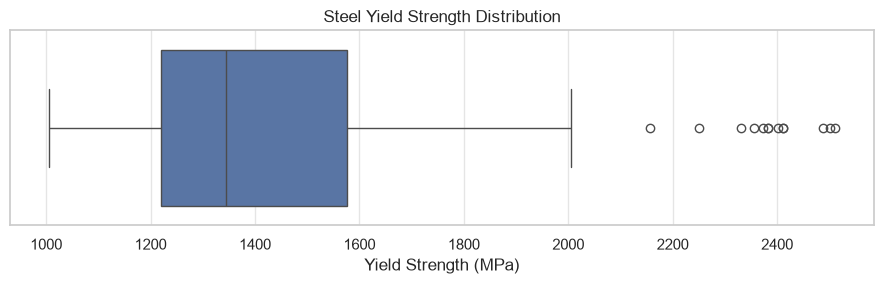

In [8]:
from matminer.datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

steels = load_dataset("matbench_steels")

# Print example datapoint
print("Example datapoint:")
print("Composition:", steels.iloc[0]["composition"])
print("Yield Strength:", steels.iloc[0]["yield strength"])

# Check viable datapoints
valid_composition = (
    steels["composition"].notna()
    & steels["composition"].astype(str).str.strip().ne("")
)

valid_yield = (
    pd.to_numeric(steels["yield strength"], errors="coerce").notna()
    & (pd.to_numeric(steels["yield strength"], errors="coerce") != 0)
)

viable = valid_composition & valid_yield

print("\nTotal datapoints:", len(steels))
print("Valid compositions:", valid_composition.sum())
print("Nonzero yield strengths:", valid_yield.sum())
print("Total viable datapoints:", viable.sum())

# Use only viable datapoints
yield_strength = steels.loc[viable, "yield strength"]

sns.set_theme(style="whitegrid")

# Histogram
plt.figure(figsize=(9, 5))
sns.histplot(yield_strength, bins=40, kde=True)
plt.xlabel("Yield Strength (MPa)")
plt.ylabel("Number of Datapoints")
plt.title("Distribution of Steel Yield Strength")
plt.tight_layout()
plt.savefig("steels_histogram.png", dpi=300)
plt.show()

# Boxplot
plt.figure(figsize=(9, 3))
sns.boxplot(x=yield_strength)
plt.xlabel("Yield Strength (MPa)")
plt.title("Steel Yield Strength Distribution")
plt.tight_layout()
plt.savefig("steels_boxplot.png", dpi=300)
plt.show()